# COMP3220 Heart Disease Prediction

This notebook prepares the COMP3220 heart-disease data, compares supervised-learning models, selects a model with stratified cross-validation, and creates the Kaggle submission file.

The workflow keeps the competition test data separate until the final prediction step.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42

def resolve_project_root():
    candidates = (Path.cwd(), Path.cwd().parent)
    for candidate in candidates:
        if (candidate / "data" / "heart_train.csv").exists():
            return candidate
    raise FileNotFoundError("run this notebook from the assignment directory")

PROJECT_ROOT = resolve_project_root()
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_PATH = PROJECT_ROOT / "predictions.csv"

Matplotlib is building the font cache; this may take a moment.


## Load the data

The training file contains the target column. The competition test file contains the same input features but omits `HeartDisease`.

In [2]:
train_df = pd.read_csv(DATA_DIR / "heart_train.csv")
test_df = pd.read_csv(DATA_DIR / "heart_test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("training shape:", train_df.shape)
print("competition shape:", test_df.shape)
display(train_df.head())
display(test_df.head())

training shape: (818, 13)
competition shape: (100, 12)


,PatientId,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,0,34,M,ATA,150,214,0,ST,168,N,0.0,Up,0
1,1,59,M,ASY,178,0,1,LVH,120,Y,0.0,Flat,1
2,2,58,M,ASY,115,0,1,Normal,138,N,0.5,Up,1
3,3,60,M,ASY,130,253,0,Normal,144,Y,1.4,Up,1
4,4,52,M,ASY,165,0,1,Normal,122,Y,1.0,Up,1


,PatientId,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,818,36,M,NAP,112,340,0,Normal,184,N,1.0,Flat
1,819,63,M,ASY,170,177,0,Normal,84,Y,2.5,Down
2,820,58,M,ASY,114,318,0,ST,140,N,4.4,Down
3,821,64,M,ASY,144,0,0,ST,122,Y,1.0,Flat
4,822,46,M,ASY,118,186,0,Normal,124,N,0.0,Flat


## Audit the data

The audit records missing values, duplicates, ranges, and zero sentinels before preprocessing changes the feature values.

In [3]:
def audit_frame(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "unique": frame.nunique(dropna=False),
    })

def zero_counts(frame, columns):
    return pd.Series({column: int(frame[column].eq(0).sum()) for column in columns})

numeric_columns = ["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak", "HeartDisease"]
display(audit_frame(train_df))
print("duplicate training rows:", int(train_df.duplicated().sum()))
print("duplicate competition rows:", int(test_df.duplicated().sum()))
display(train_df[numeric_columns].describe().T)
display(zero_counts(train_df, numeric_columns))
display(train_df["HeartDisease"].value_counts().rename_axis("HeartDisease").to_frame("count"))

,dtype,missing,unique
PatientId,int64,0,818
Age,int64,0,50
Sex,str,0,2
ChestPainType,str,0,4
RestingBP,int64,0,67
Cholesterol,int64,0,215
FastingBS,int64,0,2
RestingECG,str,0,3
MaxHR,int64,0,117
ExerciseAngina,str,0,2


duplicate training rows: 0
duplicate competition rows: 0


,count,mean,std,min,25%,50%,75%,max
Age,818.0,53.512225,9.494595,28.0,47.00,54.0,60.00,77.0
RestingBP,818.0,132.506112,18.690105,0.0,120.00,130.0,140.00,200.0
Cholesterol,818.0,197.960880,108.132239,0.0,173.25,221.0,265.75,603.0
FastingBS,818.0,0.229829,0.420980,0.0,0.00,0.0,0.00,1.0
MaxHR,818.0,137.122249,25.609098,60.0,120.00,138.0,156.00,202.0
Oldpeak,818.0,0.878851,1.068329,-2.6,0.00,0.5,1.50,6.2
HeartDisease,818.0,0.545232,0.498254,0.0,0.00,1.0,1.00,1.0


Age               0
RestingBP         1
Cholesterol     151
FastingBS       630
MaxHR             0
Oldpeak         328
HeartDisease    372
dtype: int64

,count
HeartDisease,
1,446
0,372


`RestingBP = 0` and `Cholesterol = 0` represent invalid measurements in this dataset, so the preprocessing pipeline will treat those values as missing and impute them from the training data. `FastingBS = 0` and `Oldpeak = 0` represent valid observations and stay unchanged.

In [4]:
FEATURE_COLUMNS = [
    "Age",
    "Sex",
    "ChestPainType",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "RestingECG",
    "MaxHR",
    "ExerciseAngina",
    "Oldpeak",
    "ST_Slope",
]
NUMERIC_FEATURES = ["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak"]
CATEGORICAL_FEATURES = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
INVALID_ZERO_COLUMNS = ["RestingBP", "Cholesterol"]

# keep the patient identifier out of the feature matrix
X = train_df[FEATURE_COLUMNS].copy()
y = train_df["HeartDisease"].astype(int)
competition_X = test_df[FEATURE_COLUMNS].copy()

assert "PatientId" not in X.columns
assert set(X.columns) == set(competition_X.columns)
print("feature columns:", list(X.columns))

feature columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope']


## Split the training data and define preprocessing

The stratified split preserves the target proportions. The preprocessing steps fit inside each model pipeline, so imputation, encoding, and scaling use training data only.

In [5]:
# use stratification to preserve the target balance
X_train, X_test_split, y_train, y_test_split = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

def replace_invalid_zeros(frame):
    cleaned = frame.copy()
    for column in INVALID_ZERO_COLUMNS:
        if column in cleaned.columns:
            cleaned[column] = cleaned[column].replace(0, np.nan)
    return cleaned

def make_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("invalid_zero_to_nan", FunctionTransformer(replace_invalid_zeros, feature_names_out="one-to-one")),
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", make_encoder()),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ])

## Train the required models

The simple neural network uses one small hidden layer. The larger network uses two layers with about 100 neurons each so the comparison addresses the assignment objective.

In [6]:
def make_pipeline(estimator):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", estimator),
    ])

models = {
    "logistic regression": make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "simple neural network": make_pipeline(MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, random_state=RANDOM_STATE)),
    "larger neural network": make_pipeline(MLPClassifier(hidden_layer_sizes=(100, 100), max_iter=2000, random_state=RANDOM_STATE)),
    "svm": make_pipeline(SVC()),
    "random forest": make_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "knn": make_pipeline(KNeighborsClassifier()),
}

def evaluate_model(name, model, features, labels):
    predictions = model.predict(features)
    return {
        "model": name,
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
        "confusion_matrix": confusion_matrix(labels, predictions),
    }

baseline_results = []
baseline_confusion_matrices = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    result = evaluate_model(name, model, X_test_split, y_test_split)
    baseline_confusion_matrices[name] = result.pop("confusion_matrix")
    baseline_results.append(result)

baseline_metrics = pd.DataFrame(baseline_results).sort_values("f1", ascending=False).reset_index(drop=True)
display(baseline_metrics.style.format({column: "{:.3f}" for column in ["accuracy", "precision", "recall", "f1"]}))

,model,accuracy,precision,recall,f1
0,svm,0.890,0.890,0.910,0.900
1,random forest,0.884,0.907,0.876,0.891
2,simple neural network,0.878,0.879,0.899,0.889
3,logistic regression,0.872,0.886,0.876,0.881
4,knn,0.860,0.875,0.865,0.870
5,larger neural network,0.823,0.849,0.820,0.834


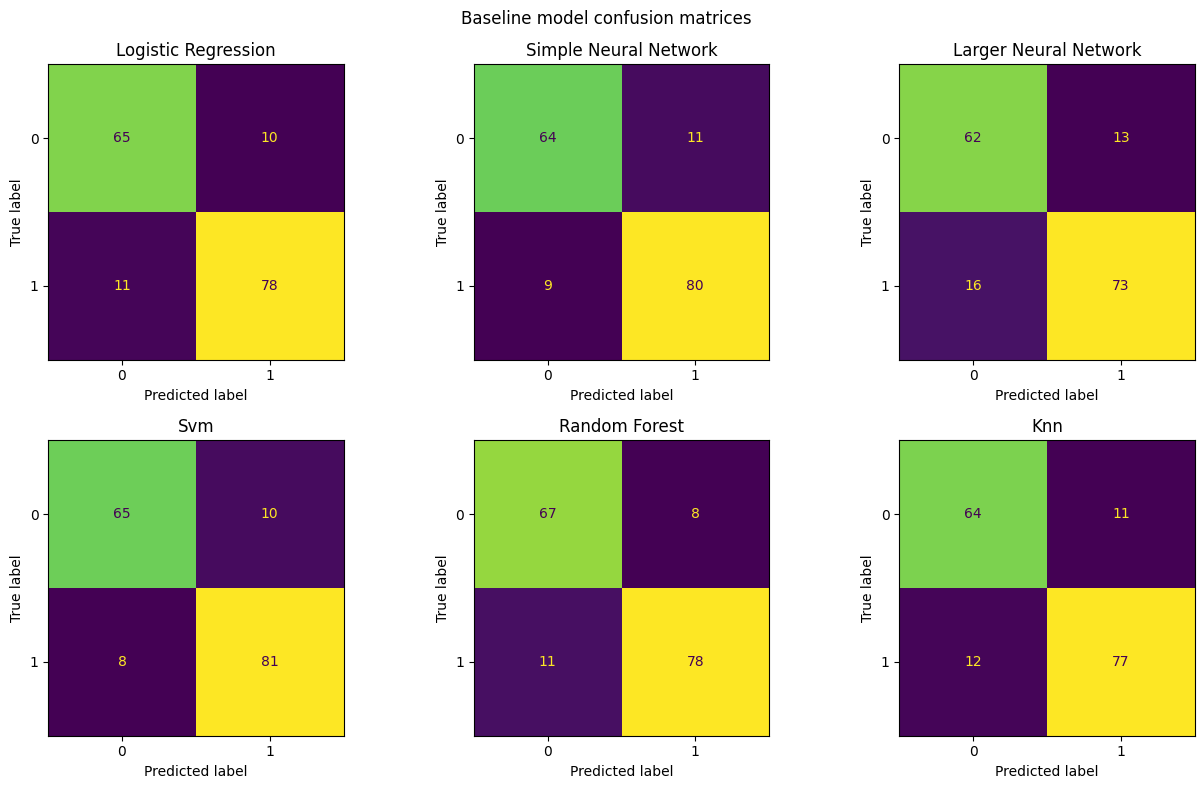

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for axis, (name, matrix) in zip(axes.ravel(), baseline_confusion_matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=[0, 1]).plot(ax=axis, colorbar=False)
    axis.set_title(name.title())
fig.suptitle("Baseline model confusion matrices")
fig.tight_layout()
plt.show()

## Tune models with five-fold cross-validation

Grid search evaluates each candidate setting on several training folds. The held-out split remains available for one final comparison after tuning. F1 is the selection score because it balances false positives and false negatives.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuning_plan = {
    "logistic regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"model__C": [0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]},
    ),
    "svm": (
        SVC(),
        {"model__C": [0.1, 1.0, 10.0], "model__kernel": ["linear", "rbf"]},
    ),
    "random forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"model__n_estimators": [200, 400], "model__max_depth": [None, 5, 10], "model__class_weight": [None, "balanced"]},
    ),
    "knn": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 7, 9], "model__weights": ["uniform", "distance"]},
    ),
}

searches = {}
search_rows = []
for name, (estimator, parameter_grid) in tuning_plan.items():
    search = GridSearchCV(
        estimator=make_pipeline(estimator),
        param_grid=parameter_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    search_rows.append({
        "model": name,
        "best_cv_f1": search.best_score_,
        "best_parameters": search.best_params_,
    })

grid_results = pd.DataFrame(search_rows).sort_values("best_cv_f1", ascending=False).reset_index(drop=True)
display(grid_results)

,model,best_cv_f1,best_parameters
0,random forest,0.877802,"{'model__class_weight': 'balanced', 'model__ma..."
1,svm,0.870646,"{'model__C': 0.1, 'model__kernel': 'linear'}"
2,logistic regression,0.865030,"{'model__C': 0.1, 'model__class_weight': None}"
3,knn,0.858719,"{'model__n_neighbors': 5, 'model__weights': 'd..."


In [9]:
tuned_results = []
tuned_confusion_matrices = {}
for name, search in searches.items():
    result = evaluate_model(name, search.best_estimator_, X_test_split, y_test_split)
    tuned_confusion_matrices[name] = result.pop("confusion_matrix")
    result["best_cv_f1"] = search.best_score_
    tuned_results.append(result)

tuned_metrics = pd.DataFrame(tuned_results).sort_values("best_cv_f1", ascending=False).reset_index(drop=True)
display(tuned_metrics.style.format({column: "{:.3f}" for column in ["accuracy", "precision", "recall", "f1", "best_cv_f1"]}))

# select the model from cross validation before touching competition data
best_model_name = grid_results.iloc[0]["model"]
best_model = searches[best_model_name].best_estimator_
print("selected model:", best_model_name)
print("selected parameters:", searches[best_model_name].best_params_)

,model,accuracy,precision,recall,f1,best_cv_f1
0,random forest,0.890,0.908,0.888,0.898,0.878
1,svm,0.878,0.897,0.876,0.886,0.871
2,logistic regression,0.872,0.886,0.876,0.881,0.865
3,knn,0.860,0.875,0.865,0.870,0.859


selected model: random forest
selected parameters: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__n_estimators': 400}


## Interpret the neural-network comparison

Scaling places numeric features on comparable ranges before optimization. Logistic regression and neural networks use feature values inside their parameter updates, so a feature with a larger numeric scale can dominate those updates. Standardization gives each numeric feature a comparable starting scale.

The larger network has more parameters than the small network. That capacity can learn useful patterns, but it can also fit noise in a small training set. Compare both models on the same held-out split and use the result in the report rather than assuming that more neurons improve accuracy.

## Handle class imbalance

The target distribution provides the first check. If one class becomes rare, stratified splitting and stratified cross-validation preserve its presence in each fold. Class weights can increase the penalty for mistakes on the smaller class. Resampling methods such as oversampling the minority class or undersampling the majority class can help, but they must run inside each training fold to prevent leakage. Precision, recall, F1, and the confusion matrix show trade-offs that accuracy can hide.

In [10]:
target_balance = y.value_counts().rename_axis("HeartDisease").to_frame("count")
target_balance["proportion"] = target_balance["count"] / len(y)
display(target_balance)
print("minority to majority ratio:", round(target_balance["count"].min() / target_balance["count"].max(), 3))

,count,proportion
HeartDisease,,
1,446,0.545232
0,372,0.454768


minority to majority ratio: 0.834


## Fit the selected model and create the submission

The competition rows stay isolated until this step. The selected pipeline now fits all labeled training rows, predicts the competition rows, and writes the exact columns shown in the sample submission.

In [11]:
best_model.fit(X, y)
competition_predictions = best_model.predict(competition_X).astype(int)
submission = pd.DataFrame({
    "PatientId": test_df["PatientId"],
    "HeartDisease": competition_predictions,
})

assert list(submission.columns) == list(sample_submission.columns)
assert submission["PatientId"].equals(sample_submission["PatientId"])
assert len(submission) == len(test_df)
assert submission["HeartDisease"].isin([0, 1]).all()
assert not submission.isna().any().any()

submission.to_csv(OUTPUT_PATH, index=False)
baseline_metrics.to_csv(PROJECT_ROOT / "baseline_metrics.csv", index=False)
tuned_metrics.to_csv(PROJECT_ROOT / "tuned_metrics.csv", index=False)
grid_results.to_csv(PROJECT_ROOT / "grid_search_results.csv", index=False)

print("saved:", OUTPUT_PATH)
display(submission.head())

saved: /Users/cajaun/Documents/school-workspace/Python/COMP3220/assignment-4/predictions.csv


,PatientId,HeartDisease
0,818,0
1,819,1
2,820,1
3,821,1
4,822,1


## Final checks

Before submission, save the executed notebook so the outputs show the audit, metrics, confusion matrices, grid-search results, selected model, and submission checks. Add those results to the report together with the Kaggle leaderboard screenshot and student ID numbers.